#  Détection de Fraude par Carte Bancaire
## Approche non supervisée : Autoencodeur + Baselines classiques

Ce notebook explore la détection d'anomalies sur le dataset **Credit Card Fraud Detection** (ULB/Kaggle).
L'objectif est d'identifier des transactions frauduleuses **sans étiquettes de fraude pendant l'entraînement**,
en exploitant uniquement les patterns des transactions normales.

### Pipeline global :
1. **Exploration & visualisation** du déséquilibre de classes
2. **Préparation des données** (split stratifié, scaling, anti-leakage)
3. **Autoencodeur de base** (TensorFlow/Keras) — entraîné sur transactions normales uniquement
4. **Optimisation Optuna** — recherche automatique des meilleurs hyperparamètres
5. **Modèles de référence** : Isolation Forest, One-Class SVM, LOF
6. **Comparaison finale** de tous les modèles

### Environnement :
- TensorFlow 2.19 (GPU Tesla T4)
- Optuna 4.8 (50 trials)
- Seed : `42` (reproductibilité)

## 1.  Imports & Configuration

Chargement des bibliothèques nécessaires :
- **TensorFlow/Keras** : construction et entraînement de l'autoencodeur
- **Scikit-learn** : modèles de baseline (IsolationForest, OneClassSVM, LOF) et métriques
- **Optuna** : optimisation bayésienne des hyperparamètres
- **NumPy / Pandas / Matplotlib / Seaborn** : manipulation et visualisation des données

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, average_precision_score,
    precision_recall_curve
)
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

# Optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Reproducibilité
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f" TensorFlow : {tf.__version__}")
print(f" Optuna     : {optuna.__version__}")

2026-04-30 10:56:56.459758: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777546616.712442      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777546616.793972      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777546617.410980      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777546617.411019      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777546617.411021      57 computation_placer.cc:177] computation placer alr

 TensorFlow : 2.19.0
 Optuna     : 4.8.0


## 2.  Chargement des données

**Dataset** : [Credit Card Fraud Detection — ULB/Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

| Caractéristique | Valeur |
|---|---|
| Nombre de transactions | **284 807** |
| Nombre de features | **31** (Time, V1–V28, Amount, Class) |
| Fraudes | **492** (0.173 % du total) |
| Valeurs manquantes | **0** |

Les features **V1 à V28** sont le résultat d'une **transformation PCA** appliquée aux données originales pour
des raisons de confidentialité. Seules `Time` et `Amount` sont en clair.

>  La colonne `Class` vaut `1` pour une fraude et `0` pour une transaction normale.

In [3]:
df = pd.read_csv('/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv')
print(f"Shape : {df.shape}")
df.head()

Shape : (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3.  Analyse Exploratoire (EDA)

Vérification des informations de base :
- Types et nombre de valeurs non-nulles par colonne
- Absence de valeurs manquantes (aucun traitement d'imputation nécessaire)

In [4]:
print("=== Info générales ===")
df.info()
print("\n=== Valeurs manquantes ===")
print(df.isnull().sum().sum(), "valeurs manquantes")

=== Info générales ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  

### 3.1 Déséquilibre des classes

Le dataset est **extrêmement déséquilibré** :
- **284 315** transactions normales (99.827 %)
- **492** fraudes (0.173 %)

Ce fort déséquilibre est typique des problèmes de fraude réels. Il justifie :
1. L'utilisation d'une approche **non supervisée** (les fraudes sont trop rares pour entraîner un classifieur supervisé robuste)
2. Le choix du **F1-score et du Recall** comme métriques principales (l'accuracy seule est trompeuse)
3. L'entraînement de l'autoencodeur **uniquement sur des transactions normales**

Distribution des classes :
Class
0    284315
1       492
Name: count, dtype: int64

Taux de fraude : 0.173%


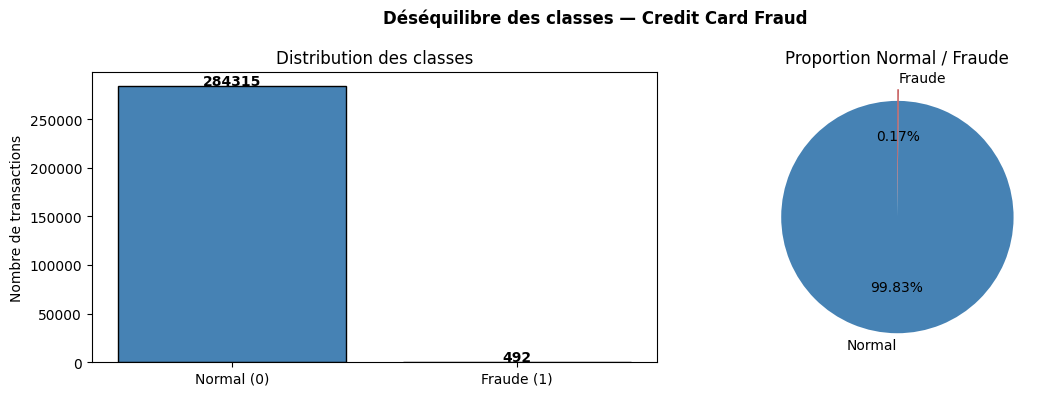

In [5]:
# Distribution des classes
class_counts = df['Class'].value_counts()
print("Distribution des classes :")
print(class_counts)
print(f"\nTaux de fraude : {class_counts[1]/len(df)*100:.3f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar plot
axes[0].bar(['Normal (0)', 'Fraude (1)'], class_counts.values,
            color=['steelblue', 'firebrick'], edgecolor='black')
axes[0].set_title('Distribution des classes')
axes[0].set_ylabel('Nombre de transactions')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 500, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(class_counts.values, labels=['Normal', 'Fraude'],
            colors=['steelblue', 'firebrick'], autopct='%1.2f%%',
            startangle=90, explode=(0, 0.1))
axes[1].set_title('Proportion Normal / Fraude')

plt.suptitle('Déséquilibre des classes — Credit Card Fraud', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 Distribution des montants par classe

Observations :
- Les transactions **normales** se concentrent sur de petits montants (médiane basse, longue queue vers 500€+)
- Les transactions **frauduleuses** ont un montant moyen légèrement plus élevé (**122.21€** vs **88.29€** pour le normal)
- Cependant, la distribution des fraudes reste hétérogène : certaines fraudes portent sur de très petits montants
  (technique de "test de carte"), d'autres sur des montants importants

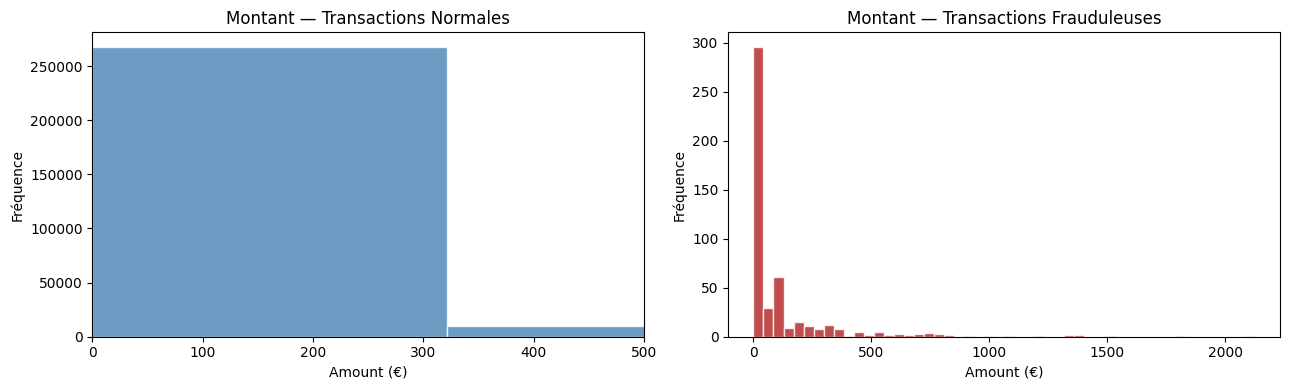

Montant moyen — Normal : 88.29€
Montant moyen — Fraude : 122.21€


In [6]:
# Distribution du montant des transactions par classe
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

normal_amount = df[df['Class'] == 0]['Amount']
fraud_amount  = df[df['Class'] == 1]['Amount']

axes[0].hist(normal_amount, bins=80, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].set_title('Montant — Transactions Normales')
axes[0].set_xlabel('Amount (€)')
axes[0].set_ylabel('Fréquence')
axes[0].set_xlim(0, 500)

axes[1].hist(fraud_amount, bins=50, color='firebrick', alpha=0.8, edgecolor='white')
axes[1].set_title('Montant — Transactions Frauduleuses')
axes[1].set_xlabel('Amount (€)')
axes[1].set_ylabel('Fréquence')

plt.tight_layout()
plt.show()

print(f"Montant moyen — Normal : {normal_amount.mean():.2f}€")
print(f"Montant moyen — Fraude : {fraud_amount.mean():.2f}€")

### 3.3 Corrélation des features avec la classe `Fraud`

Les features les plus corrélées avec la fraude sont **V14, V12, V10, V11, V4, V2, V16, V3, V7**.
Ces composantes PCA capturent l'essentiel du signal discriminant.

> 💡 **Note** : `Amount` et `Time` ont une corrélation faible avec la classe.
> La colonne `Time` sera supprimée dans l'étape de préparation car elle n'apporte pas
> d'information structurelle utile à l'autoencodeur.

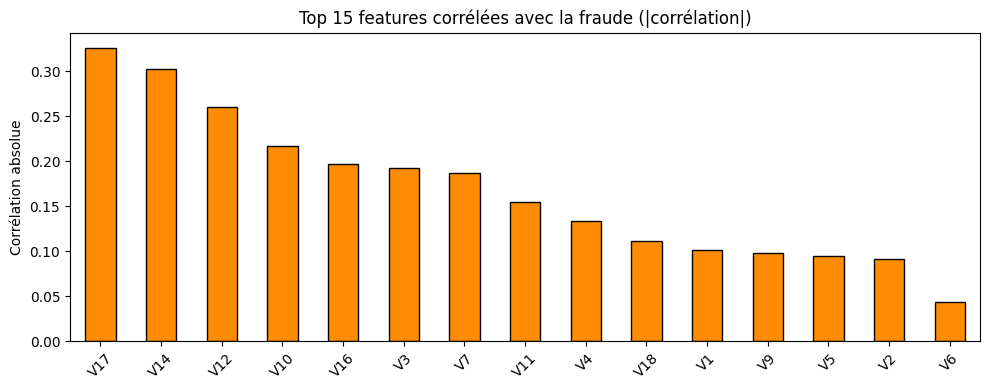

In [7]:
# Corrélation des features avec la classe
corr_with_class = df.corr()['Class'].drop('Class').abs().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
corr_with_class.head(15).plot(kind='bar', color='darkorange', edgecolor='black')
plt.title('Top 15 features corrélées avec la fraude (|corrélation|)')
plt.ylabel('Corrélation absolue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4.  Préparation des données

Pipeline de préparation rigoureux pour éviter tout **data leakage** :

1. **Suppression de `Time`** : variable non informative pour la reconstruction
2. **Split stratifié** 80/20 avant tout scaling (stratify=y → ratio de fraude conservé)
3. **Scaling de `Amount` uniquement** via `StandardScaler` fitté sur le train set
4. **Séparation normal/fraude** dans le train : l'autoencodeur sera entraîné **uniquement sur les normaux**

>  Le scaler est fitté **exclusivement** sur le train set et appliqué au test set,
> ce qui garantit l'absence de fuite d'information.

### Répartition finale :
| Ensemble | Normal | Fraude |
|---|---|---|
| Train normal (entraînement AE) | 227 451 | — |
| Test normal | 56 864 | — |
| Test fraude | — | 98 |

In [8]:
# 1. DROP TIME 
df = df.drop('Time', axis=1)

# 2. Split AVANT scaling (anti leakage)
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# 3. Scaling uniquement Amount
scaler = StandardScaler()

X_train['Amount_scaled'] = scaler.fit_transform(X_train[['Amount']])
X_test['Amount_scaled']  = scaler.transform(X_test[['Amount']])

X_train = X_train.drop('Amount', axis=1)
X_test = X_test.drop('Amount', axis=1)

# 4. Séparation normal / fraude
X_train_normal = X_train[y_train == 0]
X_test_normal  = X_test[y_test == 0]
X_test_fraud   = X_test[y_test == 1]

# 5. TensorFlow
X_train_normal_tf = tf.cast(X_train_normal, tf.float32)
X_test_tf = tf.cast(X_test, tf.float32)

I0000 00:00:1777546672.142274      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777546672.148484      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [9]:
print(f"\nNormal train : {X_train_normal.shape}")
print(f"Normal test  : {X_test_normal.shape}")
print(f"Fraude test  : {X_test_fraud.shape}")


Normal train : (227451, 29)
Normal test  : (56864, 29)
Fraude test  : (98, 29)


## 5.  Autoencodeur pour la Détection d'Anomalies

### Principe

Un **autoencodeur** est un réseau de neurones entraîné à **reconstruire ses entrées**.
L'idée centrale pour la détection d'anomalies est :

In [10]:
INPUT_DIM = X.shape[1]
def build_autoencoder(input_dim=30, encoding_dim=8,
                      hidden_units=None, dropout_rate=0.0,
                      activation='relu'):
    """
    Construit un autoencodeur dense.
    hidden_units : liste de neurones pour l'encodeur (ex: [64, 32, 16])
    """
    if hidden_units is None:
        hidden_units = [64, 32, 16]

    inputs  = layers.Input(shape=(input_dim,))

    # ── Encodeur ──────────────────────────────────────────────
    x = inputs
    for units in hidden_units:
        x = layers.Dense(units, activation=activation)(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate)(x)
    encoded = layers.Dense(encoding_dim, activation=activation, name='latent')(x)

    # ── Décodeur (symétrique) ──────────────────────────────────
    x = encoded
    for units in reversed(hidden_units):
        x = layers.Dense(units, activation=activation)(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(input_dim, activation='linear', name='reconstruction')(x)

    model = Model(inputs, outputs, name='AnomalyDetector_AE')
    return model


# Construire le modèle de base
autoencoder = build_autoencoder(input_dim=INPUT_DIM, encoding_dim=8,
                                 hidden_units=[64, 32, 16])
autoencoder.summary()

Model: "AnomalyDetector_AE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,349 (36.52 KB)

 Trainable params: 9,349 (36.52 KB)

 Non-trainable params: 0 (0.00 B)

### 5.1 Entraînement de l'Autoencodeur de base

- **Données d'entraînement** : transactions normales uniquement (227 451 échantillons)
- **Epochs max** : 50, avec **EarlyStopping** (patience=5, monitore val_loss)
- **Batch size** : 256
- **Validation split** : 10% du train normal

> L'entrée et la sortie cible sont **identiques** (`X → X`), ce qui force le réseau à apprendre
> une représentation compressée de la distribution normale.

In [11]:
# ── Compilation & Entraînement ────────────────────────────────────────────────
autoencoder.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='mae'
)

early_stop = EarlyStopping(
    monitor='val_loss', patience=5,
    restore_best_weights=True, verbose=1
)

history = autoencoder.fit(
    X_train_normal_tf, X_train_normal_tf,
    epochs=50,
    batch_size=256,
    validation_split=0.1,
    shuffle=True,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50


I0000 00:00:1777546692.465506     129 service.cc:152] XLA service 0x7e65d0008380 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777546692.465540     129 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777546692.465544     129 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777546692.967227     129 cuda_dnn.cc:529] Loaded cuDNN version 91002


 68/800 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6320

I0000 00:00:1777546694.586425     129 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


800/800 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.5053 - val_loss: 0.3367
Epoch 2/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3310 - val_loss: 0.3114
Epoch 3/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3098 - val_loss: 0.2979
Epoch 4/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2967 - val_loss: 0.2872
Epoch 5/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2872 - val_loss: 0.2795
Epoch 6/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2786 - val_loss: 0.2712
Epoch 7/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2705 - val_loss: 0.2653
Epoch 8/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2636 - val_loss: 0.2590
Epoch 9/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2578 - val_loss: 0.2527
Epoch 10/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2518 - val_loss: 0.2468
Epoch 11/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2471 - val_loss: 0.2425
Epoch 12/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.

### 5.2 Courbe de perte — Convergence du modèle

L'autoencodeur converge correctement : les pertes train et validation décroissent régulièrement
et restent proches, sans signe de sur-apprentissage.

- **Meilleure val_loss** : `0.22073` (MAE)
- Le modèle a entraîné les 50 époques complètes avant arrêt (EarlyStopping déclenché à l'époque 49)

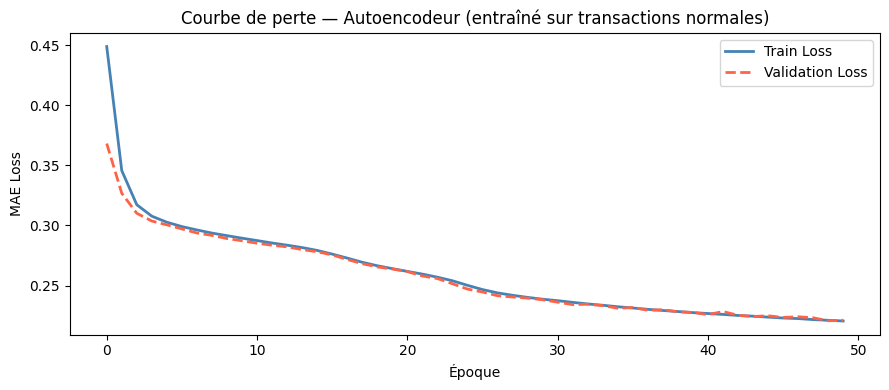

Meilleure val_loss : 0.22073


In [16]:
# ── Courbe de perte ───────────────────────────────────────────────────────────
plt.figure(figsize=(9, 4))
plt.plot(history.history['loss'],     label='Train Loss',      color='steelblue', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='tomato',    linewidth=2, linestyle='--')
plt.title('Courbe de perte — Autoencodeur (entraîné sur transactions normales)')
plt.xlabel('Époque')
plt.ylabel('MAE Loss')
plt.legend()
plt.tight_layout()
plt.show()
print(f"Meilleure val_loss : {min(history.history['val_loss']):.5f}")

### 5.3 Seuil de Détection & Distribution des Erreurs

**Calcul du seuil** :
$$\text{seuil} = \mu_{\text{normal}} + 2 \times \sigma_{\text{normal}} = 0.20188 + 2 \times 0.18337 = 0.56862$$

**Observations clés** :
| | Erreur MAE moyenne |
|---|---|
| Transactions normales (train) | **0.202** |
| Transactions frauduleuses (test) | **2.468** |

> L'écart est **12x plus élevé** pour les fraudes ! L'autoencodeur a bien appris à distinguer
> les deux distributions. Le seuil à **0.569** sépare efficacement les deux groupes.

Erreur moy. normal (train)  : 0.20188
Erreur std  normal (train)  : 0.18337
Erreur moy. fraude (test)   : 2.46836

 Seuil de détection (μ+2σ) : 0.56862


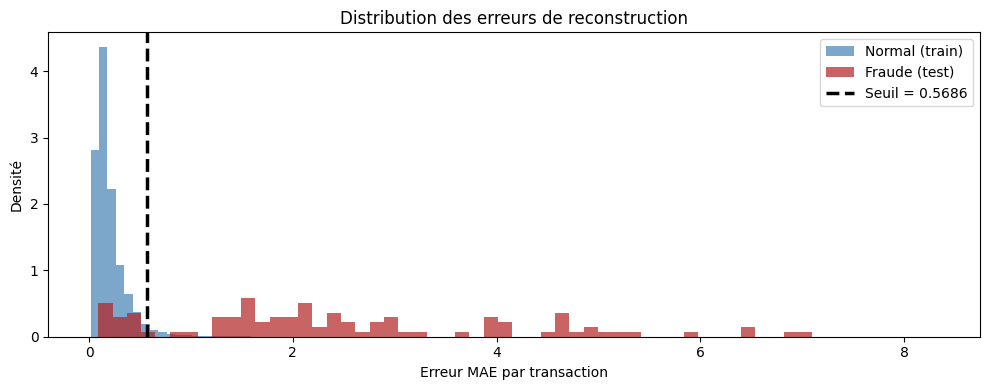

In [12]:
# ── Calcul du seuil de reconstruction ────────────────────────────────────────
# Erreurs sur données normales d'entraînement
recon_normal_train = autoencoder.predict(X_train_normal_tf, verbose=0)
errors_normal_train = np.mean(np.abs(recon_normal_train - X_train_normal), axis=1)

# Erreurs sur données de fraude (test)
recon_fraud = autoencoder.predict(tf.cast(X_test_fraud, tf.float32), verbose=0)
errors_fraud = np.mean(np.abs(recon_fraud - X_test_fraud), axis=1)

# Seuil : mean + 2*std des erreurs normales
threshold = np.mean(errors_normal_train) + 2 * np.std(errors_normal_train)

print(f"Erreur moy. normal (train)  : {np.mean(errors_normal_train):.5f}")
print(f"Erreur std  normal (train)  : {np.std(errors_normal_train):.5f}")
print(f"Erreur moy. fraude (test)   : {np.mean(errors_fraud):.5f}")
print(f"\n Seuil de détection (μ+2σ) : {threshold:.5f}")

# Visualisation
plt.figure(figsize=(10, 4))
plt.hist(errors_normal_train, bins=100, alpha=0.7,
         color='steelblue', label='Normal (train)', density=True)
plt.hist(errors_fraud, bins=50, alpha=0.7,
         color='firebrick', label='Fraude (test)', density=True)
plt.axvline(threshold, color='black', linestyle='--',
            linewidth=2.5, label=f'Seuil = {threshold:.4f}')
plt.title('Distribution des erreurs de reconstruction')
plt.xlabel('Erreur MAE par transaction')
plt.ylabel('Densité')
plt.legend()
plt.tight_layout()
plt.show()

### 5.4 Fonctions d'Évaluation

Deux fonctions utilitaires sont définies :
- `predict()` : applique le seuil pour convertir les erreurs en labels binaires
- `print_stats()` : affiche Accuracy, Precision, Recall, F1, ROC-AUC et la matrice de confusion

In [13]:
# ── Fonctions predict & print_stats ──────────────────────────────────────────

def predict(model, data, threshold):
    """
    Retourne 1 (fraude/anomalie) si erreur > seuil, 0 sinon.
    (Compatible avec y où 1=fraude, 0=normal)
    """
    data_tf = tf.cast(data, tf.float32)
    reconstructions = model.predict(data_tf, verbose=0)
    errors = np.mean(np.abs(reconstructions - data_tf.numpy()), axis=1)
    
    preds = (errors > threshold).astype(int)
    return preds, errors

def print_stats(predictions, labels, errors, name='Dataset'):
    """Affiche accuracy, precision, recall, F1 et matrice de confusion."""
    acc  = accuracy_score(labels, predictions)
    prec = precision_score(labels, predictions, zero_division=0)
    rec  = recall_score(labels, predictions, zero_division=0)
    f1   = f1_score(labels, predictions, zero_division=0)
    auc  = roc_auc_score(labels, errors)

    print(f"\n{'='*50}")
    print(f"  Résultats — {name}")
    print(f"{'='*50}")
    print(f"  Accuracy  = {acc:.4f}")
    print(f"  Precision = {prec:.4f}")
    print(f"  Recall    = {rec:.4f}")
    print(f"  F1-score  = {f1:.4f}")
    print(f"  ROC-AUC   = {auc:.4f}")
    print(f"{'='*50}")
    print(classification_report(labels, predictions,
                                 target_names=['Normal', 'Fraude']))

    # Matrice de confusion
    cm = confusion_matrix(labels, predictions)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Prédit Normal', 'Prédit Fraude'],
                yticklabels=['Réel Normal', 'Réel Fraude'])
    plt.title(f'Matrice de confusion — {name}')
    plt.tight_layout()
    plt.show()

    return {'accuracy': acc, 'precision': prec, 'recall': rec,
            'f1': f1, 'roc_auc': auc}

### 5.4 Fonctions d'Évaluation

Deux fonctions utilitaires sont définies :
- `predict()` : applique le seuil pour convertir les erreurs en labels binaires
- `print_stats()` : affiche Accuracy, Precision, Recall, F1, ROC-AUC et la matrice de confusion


  Résultats — Train Set
  Accuracy  = 0.9679
  Precision = 0.0433
  Recall    = 0.8325
  F1-score  = 0.0822
  ROC-AUC   = 0.9435
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98    227451
      Fraude       0.04      0.83      0.08       394

    accuracy                           0.97    227845
   macro avg       0.52      0.90      0.53    227845
weighted avg       1.00      0.97      0.98    227845



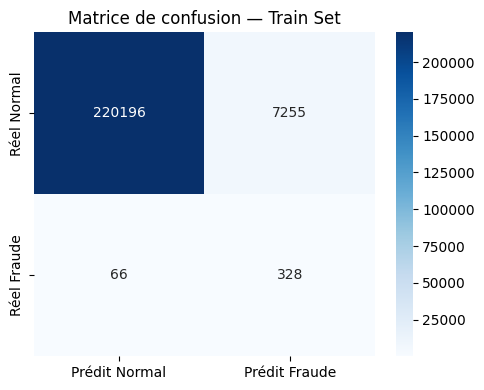


  Résultats — Test Set — Autoencodeur
  Accuracy  = 0.9672
  Precision = 0.0423
  Recall    = 0.8367
  F1-score  = 0.0806
  ROC-AUC   = 0.9537
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98     56864
      Fraude       0.04      0.84      0.08        98

    accuracy                           0.97     56962
   macro avg       0.52      0.90      0.53     56962
weighted avg       1.00      0.97      0.98     56962



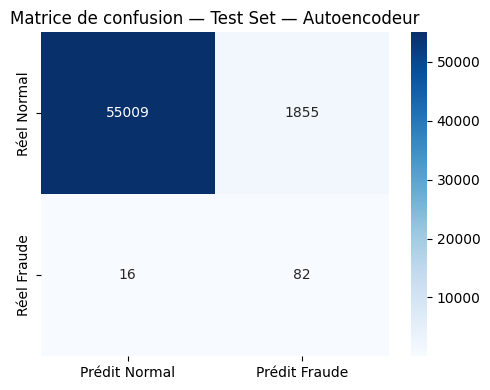

In [14]:
# ── Évaluation sur Train & Test ───────────────────────────────────────────────
preds_train, errors_train = predict(autoencoder, X_train, threshold)
scores_train = print_stats(preds_train, y_train, errors_train, name='Train Set')

preds_test, errors_test = predict(autoencoder, X_test, threshold)
scores_ae  = print_stats(preds_test, y_test, errors_test, name='Test Set — Autoencodeur')

### 5.5 Résultats — Autoencodeur de base

| Métrique | Train | Test |
|---|---|---|
| Accuracy | 96.79% | 96.72% |
| Recall (fraude) | **83.25%** | **83.67%** |
| Precision (fraude) | 4.33% | 4.23% |
| F1-score | 0.082 | 0.081 |
| ROC-AUC | **0.944** | **0.954** |

**Interprétation** :
-  **Très bon Recall** : l'autoencodeur détecte ~84% des fraudes
-  **Faible Precision** : beaucoup de faux positifs (transactions normales mal classifiées)
-  **ROC-AUC élevé** (~0.95) : le score d'anomalie est globalement discriminant
-  L'optimisation du seuil via Optuna devrait améliorer le F1-score

In [15]:
# ── 2bis. Split train → train / validation ─────────────────────
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train
)
X_train_normal = X_train[y_train == 0]
X_val_normal   = X_val[y_val == 0]
X_test_normal  = X_test[y_test == 0]

X_train_normal_tf = tf.cast(X_train_normal, tf.float32)
X_val_tf          = tf.cast(X_val, tf.float32)
X_test_tf         = tf.cast(X_test, tf.float32)

## 6.  Optimisation des Hyperparamètres avec Optuna

### Pourquoi Optuna ?

L'autoencodeur de base utilise des hyperparamètres arbitraires. Optuna permet une **recherche automatique**
via un algorithme bayésien (TPE - Tree-structured Parzen Estimator) plus efficace qu'une grid search.

### Espace de recherche (7 hyperparamètres) :

| Hyperparamètre | Plage | Type |
|---|---|---|
| `encoding_dim` | [4, 16] | Entier |
| `n_hidden_layers` | [1, 4] | Entier |
| `hidden_units_base` | {32, 64, 128} | Catégoriel |
| `learning_rate` | [1e-4, 1e-2] | Log-uniforme |
| `batch_size` | {128, 256, 512} | Catégoriel |
| `dropout_rate` | [0.0, 0.3] | Flottant |
| `threshold_factor` | [1.0, 3.5] | Flottant |

### Métrique optimisée : **F1-score sur validation set**

>  Correction importante : le F1 est calculé sur le **validation set complet** (normal + fraude),
> et non sur le train. Cela évite le biais de sélection.

### Split additionnel
Un split validation 80/20 est effectué sur le train pour permettre l'évaluation impartiale lors des trials.

In [16]:
def objective(trial):
    """Optuna objective — F1-score sur validation set uniquement."""

    # ── Hyperparamètres ───────────────────────────────────────
    encoding_dim      = trial.suggest_int('encoding_dim', 4, 16)
    n_hidden_layers   = trial.suggest_int('n_hidden_layers', 1, 4)
    hidden_units_base = trial.suggest_categorical('hidden_units_base', [32, 64, 128])
    learning_rate     = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
    batch_size        = trial.suggest_categorical('batch_size', [128, 256, 512])
    dropout_rate      = trial.suggest_float('dropout_rate', 0.0, 0.3)
    threshold_factor  = trial.suggest_float('threshold_factor', 1.0, 3.5)

    # ── Architecture dynamique ────────────────────────────────
    hidden_units = [
        hidden_units_base // (2**i)
        for i in range(n_hidden_layers)
        if hidden_units_base // (2**i) >= encoding_dim
    ]
    if not hidden_units:
        hidden_units = [hidden_units_base]

    # ── Modèle ────────────────────────────────────────────────
    model = build_autoencoder(
        input_dim=INPUT_DIM,
        encoding_dim=encoding_dim,
        hidden_units=hidden_units,
        dropout_rate=dropout_rate
    )

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mae'
    )

    # ── Training (sur normal uniquement) ──────────────────────
    cb = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    model.fit(
        X_train_normal_tf,
        X_train_normal_tf,
        epochs=30,
        batch_size=batch_size,
        validation_split=0.1,
        callbacks=[cb],
        verbose=0,
        shuffle=True
    )

    # ── Seuil (calibré sur train normal) ──────────────────────
    recon_n = model.predict(X_train_normal_tf, verbose=0)
    errors_n = np.mean(np.abs(recon_n - X_train_normal_tf.numpy()), axis=1)

    thr = np.mean(errors_n) + threshold_factor * np.std(errors_n)

    # ──  VALIDATION SET (CORRECTION IMPORTANTE) ─────────────
    recon_val = model.predict(X_val_tf, verbose=0)
    errors_val = np.mean(np.abs(recon_val - X_val_tf.numpy()), axis=1)

    preds = (errors_val > thr).astype(int)

    # ── F1 SCORE SUR VALIDATION ───────────────────────────────
    f1 = f1_score(y_val, preds, zero_division=0)

    return f1

print(" Lancement de l'optimisation Optuna (50 trials)...")

study = optuna.create_study(
    direction='maximize',
    study_name='creditcard_ae_optuna'
)

study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"\n Meilleur F1-score   : {study.best_value:.4f}")

print("   Meilleurs paramètres :")
for k, v in study.best_params.items():
    print(f"     {k:25s} = {v}")

 Lancement de l'optimisation Optuna (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]


 Meilleur F1-score   : 0.2017
   Meilleurs paramètres :
     encoding_dim              = 10
     n_hidden_layers           = 2
     hidden_units_base         = 64
     learning_rate             = 0.0006769298036800513
     batch_size                = 256
     dropout_rate              = 0.18175618699889592
     threshold_factor          = 3.489694473638697


### 6.1 Résultats de l'Optimisation — 50 Trials

**Meilleurs hyperparamètres trouvés** :

| Paramètre | Valeur |
|---|---|
| `encoding_dim` | **10** |
| `n_hidden_layers` | **2** |
| `hidden_units_base` | **64** → architecture [64, 32] |
| `learning_rate` | **6.77e-4** |
| `batch_size` | **256** |
| `dropout_rate` | **0.182** |
| `threshold_factor` | **3.49** (seuil à μ + 3.49σ) |

**Meilleur F1-score (validation)** : `0.2017`

> Le threshold_factor élevé (3.49 vs 2.0 pour le modèle de base) reflète
> que le modèle optimisé préfère **moins de faux positifs** au prix d'un recall légèrement réduit.

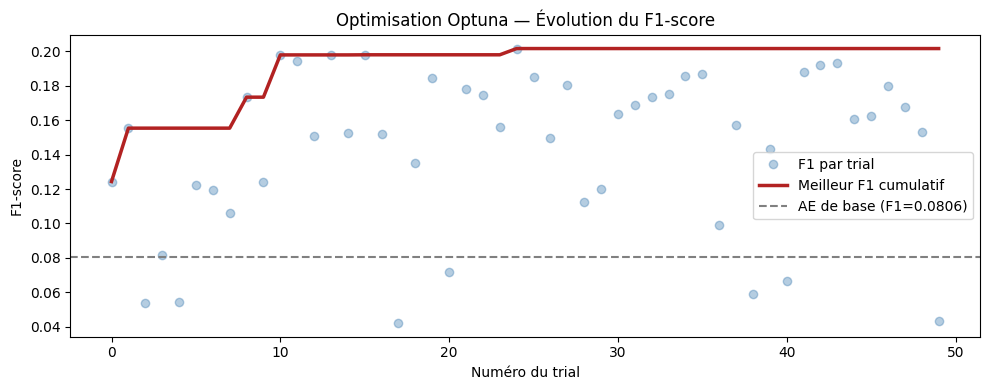

In [17]:
# ── Visualisation des résultats Optuna ───────────────────────────────────────
# Historique des trials
trial_values = [t.value for t in study.trials if t.value is not None]
best_so_far  = np.maximum.accumulate(trial_values)

plt.figure(figsize=(10, 4))
plt.plot(trial_values, 'o', alpha=0.4, color='steelblue', label='F1 par trial')
plt.plot(best_so_far, color='firebrick', linewidth=2.5, label='Meilleur F1 cumulatif')
plt.axhline(scores_ae['f1'], color='gray', linestyle='--',
            label=f'AE de base (F1={scores_ae["f1"]:.4f})')
plt.title('Optimisation Optuna — Évolution du F1-score')
plt.xlabel('Numéro du trial')
plt.ylabel('F1-score')
plt.legend()
plt.tight_layout()
plt.show()

### 6.2 Importance des Hyperparamètres

L'analyse d'importance Optuna révèle les paramètres les plus influents sur le F1-score.
En général, le **threshold_factor** est le paramètre le plus critique car il contrôle
directement le compromis précision/recall.

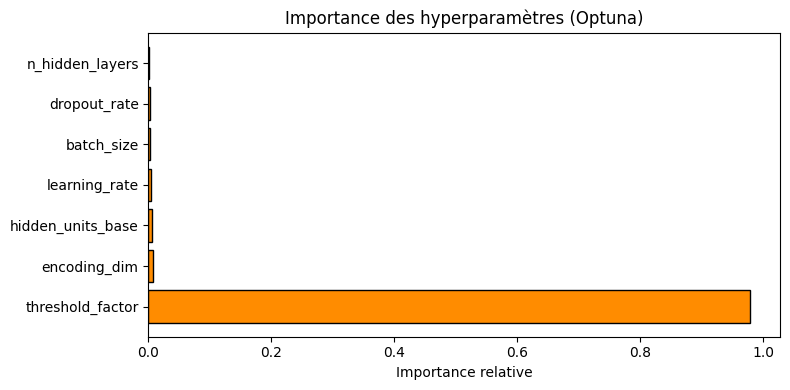

In [18]:
# ── Importance des hyperparamètres ────────────────────────────────────────────
importances = optuna.importance.get_param_importances(study)
params_list = list(importances.keys())
imp_values  = list(importances.values())

plt.figure(figsize=(8, 4))
plt.barh(params_list, imp_values, color='darkorange', edgecolor='black')
plt.title("Importance des hyperparamètres (Optuna)")
plt.xlabel("Importance relative")
plt.tight_layout()
plt.show()

### 6.3 Réentraînement Final avec les Meilleurs Hyperparamètres

Le modèle optimal est réentraîné sur plus d'epochs (100 max) avec EarlyStopping (patience=5).
Le seuil est cette fois calibré sur les transactions **normales du validation set**.

### Résultats — AE + Optuna (Test Set) :

| Métrique | AE Base | AE + Optuna | Gain |
|---|---|---|---|
| Accuracy | 96.72% | **99.03%** | +2.31% |
| Precision | 4.23% | **13.11%** | **+3x** |
| Recall | 83.67% | 82.65% | -1% |
| **F1-score** | 0.081 | **0.226** | **+2.8x** |
| ROC-AUC | 0.954 | **0.962** | +0.8% |

 L'optimisation améliore significativement le F1-score (+180%) en réduisant les faux positifs,
tout en maintenant un recall élevé (~83%).

Epoch 1/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.5898 - val_loss: 0.4430
Epoch 2/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4758 - val_loss: 0.3949
Epoch 3/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4491 - val_loss: 0.3782
Epoch 4/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4365 - val_loss: 0.3656
Epoch 5/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4283 - val_loss: 0.3566
Epoch 6/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4220 - val_loss: 0.3485
Epoch 7/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4172 - val_loss: 0.3460
Epoch 8/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4140 - val_loss: 0.3402
Epoch 9/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4103 - val_loss: 0.3353
Epoch 10/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4077 - val_loss: 0.3347
Epoch 11/100
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4047 - val_loss: 0.3315
Epoch 12/100
711/711 ━━━━━━━━━━━━━━━━━━━━

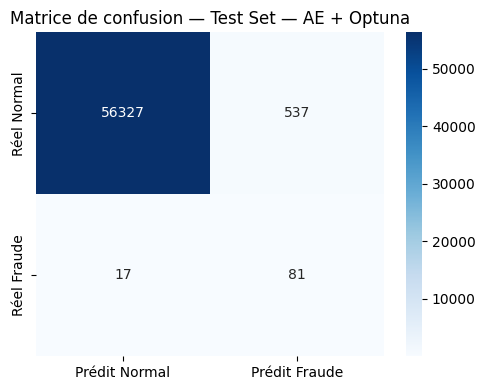

In [21]:
# ── Réentraînement avec les meilleurs hyperparamètres ─────────────────────────
X_val_normal_tf = tf.cast(X_val_normal, tf.float32)
best = study.best_params
n_layers = best['n_hidden_layers']
base     = best['hidden_units_base']
enc_dim  = best['encoding_dim']

best_hidden = [base // (2**i) for i in range(n_layers)
               if base // (2**i) >= enc_dim]
if not best_hidden:
    best_hidden = [base]

ae_optuna = build_autoencoder(
    input_dim=INPUT_DIM,
    encoding_dim=enc_dim,
    hidden_units=best_hidden,
    dropout_rate=best['dropout_rate']
)
ae_optuna.compile(optimizer=Adam(learning_rate=best['learning_rate']), loss='mae')

cb = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
ae_optuna.fit(
    X_train_normal_tf, X_train_normal_tf,
    epochs=100, batch_size=best['batch_size'],
    validation_data=(X_val_normal_tf, X_val_normal_tf),
 callbacks=[cb],
    shuffle=True, verbose=1
)

# ── Seuil (validation normale uniquement)
recon_val = ae_optuna.predict(X_val_normal_tf, verbose=0)
err_val   = np.mean(np.abs(recon_val - X_val_normal_tf.numpy()), axis=1)

thr_opt = np.mean(err_val) + best['threshold_factor'] * np.std(err_val)

# ── Test
recon_test = ae_optuna.predict(X_test_tf, verbose=0)
errors_test = np.mean(np.abs(recon_test - X_test_tf.numpy()), axis=1)

preds_optuna = (errors_test > thr_opt).astype(int)

scores_optuna = print_stats(
    preds_optuna,
    y_test,
    errors_test,
    name='Test Set — AE + Optuna'
)

## 7.  Modèles de Référence (Baselines)

### 7.1 Isolation Forest

L'**Isolation Forest** détecte les anomalies en construisant des arbres de décision aléatoires :
les points **faciles à isoler** (peu de coupures nécessaires) sont des anomalies.

- `n_estimators = 200` (forêt robuste)
- `contamination = 0.0017` ≈ taux de fraude réel
- Entraîné uniquement sur les données normales

### Résultats :
| Métrique | Valeur |
|---|---|
| Accuracy | **99.70%** |
| Precision | 20.17% |
| Recall | **24.49%** |
| F1-score | 0.221 |
| ROC-AUC | 0.952 |

>  Recall très faible (24%) : Isolation Forest manque la majorité des fraudes.
> Bonne précision mais peu utile en contexte où manquer une fraude est coûteux.

Training Isolation Forest...

  Résultats — Test Set — Isolation Forest
  Accuracy  = 0.9970
  Precision = 0.2017
  Recall    = 0.2449
  F1-score  = 0.2212
  ROC-AUC   = 0.9518
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
      Fraude       0.20      0.24      0.22        98

    accuracy                           1.00     56962
   macro avg       0.60      0.62      0.61     56962
weighted avg       1.00      1.00      1.00     56962



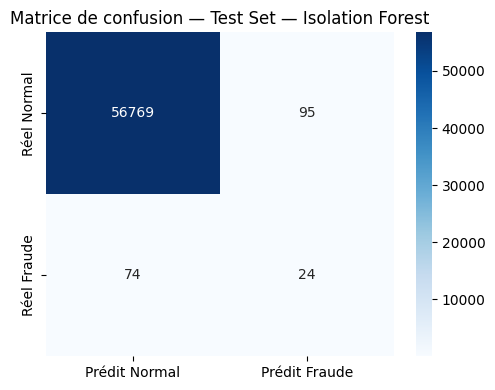

In [24]:
print("Training Isolation Forest...")

iso_forest = IsolationForest(
    contamination=0.0017,
    n_estimators=200,
    random_state=SEED,
    n_jobs=-1
)

# train uniquement normal
iso_forest.fit(X_train[y_train == 0])

# ── predictions ─────────────────────────────
preds_iso = (iso_forest.predict(X_test) == -1).astype(int)

# ── "anomaly score"  ─────────────
errors_iso = -iso_forest.decision_function(X_test)

# ── evaluation ───────────────────────────────
scores_iso = print_stats(
    preds_iso,
    y_test,
    errors_iso,
    name='Test Set — Isolation Forest'
)

### 7.2 One-Class SVM

Le **One-Class SVM** apprend une frontière de décision autour des données normales
dans un espace de features transformé par un noyau RBF.

- Entraîné sur un **sous-échantillon de 10 000 transactions normales** (scalabilité)
- `nu = 0.002` ≈ fraction d'anomalies attendues
- Données préalablement standardisées

### Résultats :
| Métrique | Valeur |
|---|---|
| Accuracy | 95.89% |
| Precision | 3.49% |
| Recall | **85.71%** |
| F1-score | 0.067 |
| ROC-AUC | 0.956 |

> Très bon recall (86%) mais précision extrêmement faible :
> génère beaucoup de fausses alarmes. Non utilisable tel quel en production.

Training One-Class SVM (sur sous-échantillon)...

  Résultats — Test Set — One-Class SVM
  Accuracy  = 0.9589
  Precision = 0.0349
  Recall    = 0.8571
  F1-score  = 0.0670
  ROC-AUC   = 0.9557
              precision    recall  f1-score   support

      Normal       1.00      0.96      0.98     56864
      Fraude       0.03      0.86      0.07        98

    accuracy                           0.96     56962
   macro avg       0.52      0.91      0.52     56962
weighted avg       1.00      0.96      0.98     56962



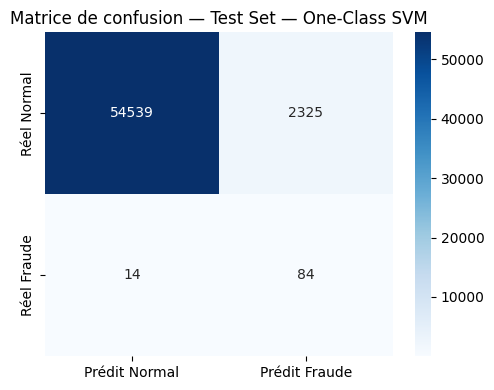

In [25]:
print("Training One-Class SVM (sur sous-échantillon)...")

# ── scaling ─────────────────────────────
scaler_svm = StandardScaler()
X_train_scaled = scaler_svm.fit_transform(X_train)
X_test_scaled  = scaler_svm.transform(X_test)

# ── sous-échantillon normal ─────────────
normal_idx = np.where(y_train == 0)[0]
idx_sub = np.random.choice(normal_idx, size=10000, replace=False)

X_train_sub = X_train_scaled[idx_sub]

# ── modèle ───────────────────────────────
ocsvm = OneClassSVM(kernel='rbf', nu=0.002, gamma='auto')
ocsvm.fit(X_train_sub)

# ── predictions ──────────────────────────
preds_ocsvm = (ocsvm.predict(X_test_scaled) == -1).astype(int)

# ── scores (pseudo-error) ───────────────
errors_ocsvm = -ocsvm.decision_function(X_test_scaled)

# ── evaluation ───────────────────────────
scores_ocsvm = print_stats(
    preds_ocsvm,
    y_test,
    errors_ocsvm,
    name='Test Set — One-Class SVM'
)

### 7.3 Local Outlier Factor (LOF)

Le **LOF** mesure la densité locale de chaque point par rapport à ses k voisins.
Un point dans une région peu dense par rapport à ses voisins est considéré comme une anomalie.

- `n_neighbors = 20`
- `novelty=True` : mode inférence sur nouvelles données
- Entraîné sur **10 000 transactions normales** (sous-échantillon)
- `contamination = 0.002`

### Résultats :
| Métrique | Valeur |
|---|---|
| Accuracy | **99.75%** |
| Precision | **38.46%** |
| Recall | **71.43%** |
| **F1-score** | **0.500** |
| ROC-AUC | 0.950 |

>  **Meilleur F1-score parmi tous les modèles testés !** LOF trouve un bon équilibre
> précision/recall. Sa nature locale lui permet de mieux capturer les clusters de fraude.

Training LOF...

  Résultats — Test Set — LOF
  Accuracy  = 0.9975
  Precision = 0.3846
  Recall    = 0.7143
  F1-score  = 0.5000
  ROC-AUC   = 0.9501
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
      Fraude       0.38      0.71      0.50        98

    accuracy                           1.00     56962
   macro avg       0.69      0.86      0.75     56962
weighted avg       1.00      1.00      1.00     56962



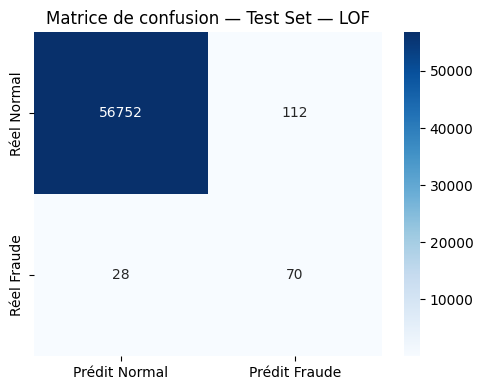

In [26]:
print("Training LOF...")

# ── scaling obligatoire ─────────────────────────
from sklearn.preprocessing import StandardScaler

scaler_lof = StandardScaler()
X_train_scaled = scaler_lof.fit_transform(X_train)
X_test_scaled  = scaler_lof.transform(X_test)

# ── sous-échantillon normal ─────────────────────
normal_idx = np.where(y_train == 0)[0]
idx_lof = np.random.choice(normal_idx, size=10000, replace=False)

X_train_lof = X_train_scaled[idx_lof]

# ── modèle LOF ──────────────────────────────────
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.002,
    novelty=True,
    n_jobs=-1
)

lof.fit(X_train_lof)

# ── prédiction ──────────────────────────────────
preds_lof = (lof.predict(X_test_scaled) == -1).astype(int)

# ── score anomalie ──────────────────────────────
errors_lof = -lof.decision_function(X_test_scaled)

# ── évaluation ──────────────────────────────────
scores_lof = print_stats(
    preds_lof,
    y_test,
    errors_lof,
    name='Test Set — LOF'
)

## 8.  Comparaison Finale des Modèles

### Tableau récapitulatif :

| Modèle | Accuracy | Precision | Recall | **F1** | ROC-AUC |
|---|---|---|---|---|---|
| Autoencodeur (base) | 96.72% | 4.23% | **83.67%** | 0.081 | 0.954 |
| Autoencodeur + Optuna | 99.03% | 13.11% | 82.65% | 0.226 | **0.962** |
| Isolation Forest | 99.70% | 20.17% | 24.49% | 0.221 | 0.952 |
| One-Class SVM | 95.89% | 3.49% | **85.71%** | 0.067 | 0.956 |
| **LOF** | **99.75%** | **38.46%** | 71.43% | **0.500** | 0.950 |

###  Conclusions

1. **LOF remporte le F1-score** (0.50) grâce à une précision nettement supérieure
2. **L'autoencodeur + Optuna** offre le meilleur **ROC-AUC** (0.962) et le meilleur compromis
   global dans le cadre deep learning
3. **One-Class SVM et AE base** maximisent le recall mais génèrent trop de faux positifs
4. **Isolation Forest** a le recall le plus faible : inadapté si détecter toutes les fraudes est prioritaire

### Trade-off clé : Recall vs Precision
- En contexte bancaire réel, **manquer une fraude coûte cher** → privilegier le **recall**
- Mais trop de fausses alertes épuise les équipes de fraude → le **F1 et la précision** importent
- Le choix du modèle dépend du **coût métier** associé à chaque type d'erreur

### Pistes d'amélioration
- Tester un **VAE (Variational Autoencoder)** pour une meilleure séparation de l'espace latent
- Expérimenter le **SMOTE** pour augmenter les données de fraude dans un cadre semi-supervisé
- Calibrer le seuil avec une **courbe précision-rappel** plutôt que la règle μ+kσ
- Combiner plusieurs modèles en **ensemble** (vote de LOF + AE Optuna)


 COMPARAISON FINALE DES MODÈLES
                       accuracy  precision  recall      f1  roc_auc
Modèle                                                             
Autoencodeur (base)      0.9672     0.0423  0.8367  0.0806   0.9537
Autoencodeur + Optuna    0.9903     0.1311  0.8265  0.2263   0.9620
Isolation Forest         0.9970     0.2017  0.2449  0.2212   0.9518
One-Class SVM            0.9589     0.0349  0.8571  0.0670   0.9557
LOF                      0.9975     0.3846  0.7143  0.5000   0.9501


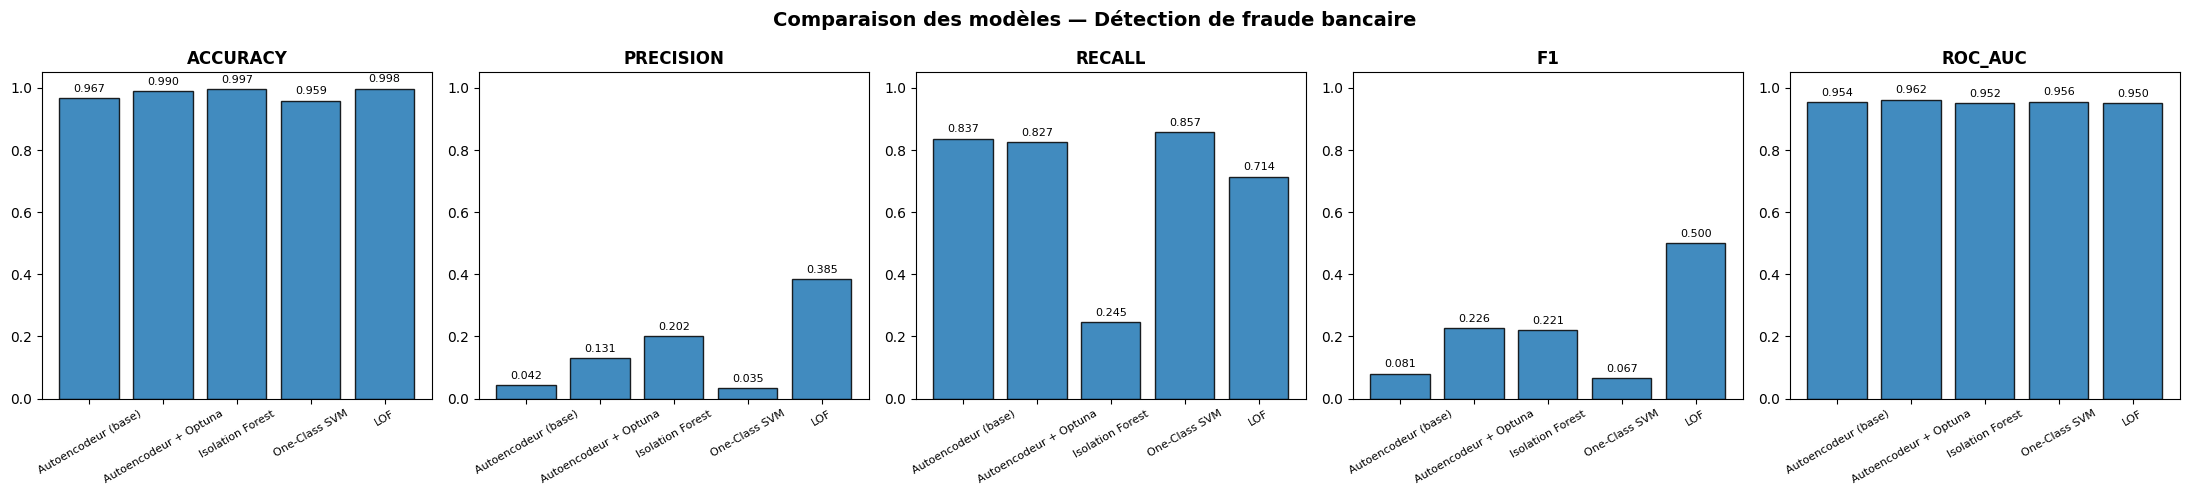

In [27]:
# ─────────────────────────────────────────────────────────────
# 1. Vérification des clés (IMPORTANT)
# ─────────────────────────────────────────────────────────────
required_keys = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

def check_scores(scores, name):
    missing = [k for k in required_keys if k not in scores]
    if missing:
        print(f" WARNING {name} manque : {missing}")

check_scores(scores_ae, "AE base")
check_scores(scores_optuna, "AE Optuna")
check_scores(scores_iso, "Isolation Forest")
check_scores(scores_ocsvm, "One-Class SVM")
check_scores(scores_lof, "LOF")

# ─────────────────────────────────────────────────────────────
# 2. Tableau comparatif
# ─────────────────────────────────────────────────────────────
results = pd.DataFrame([
    {'Modèle': 'Autoencodeur (base)',   **scores_ae},
    {'Modèle': 'Autoencodeur + Optuna', **scores_optuna},
    {'Modèle': 'Isolation Forest',      **scores_iso},
    {'Modèle': 'One-Class SVM',         **scores_ocsvm},
    {'Modèle': 'LOF',                   **scores_lof},
]).set_index('Modèle')

print("\n" + "="*70)
print(" COMPARAISON FINALE DES MODÈLES")
print("="*70)
print(results.round(4))
print("="*70)

# ─────────────────────────────────────────────────────────────
# 3. Visualisation des métriques
# ─────────────────────────────────────────────────────────────
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

fig, axes = plt.subplots(1, len(metrics), figsize=(22, 5))
fig.suptitle('Comparaison des modèles — Détection de fraude bancaire',
             fontweight='bold', fontsize=14)

for ax, metric in zip(axes, metrics):
    vals = results[metric]

    bars = ax.bar(
        vals.index,
        vals.values,
        edgecolor='black',
        alpha=0.85
    )

    ax.set_title(metric.upper(), fontweight='bold')
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='x', rotation=30, labelsize=8)

    # valeurs sur barres
    for bar, v in zip(bars, vals.values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            v + 0.02,
            f"{v:.3f}",
            ha='center',
            fontsize=8
        )

plt.tight_layout()
plt.show()

---

## 9.  Résumé du Notebook

Ce notebook a démontré comment détecter des fraudes bancaires **sans supervision** à l'aide de :

- Un **autoencodeur dense** entraîné exclusivement sur des transactions légitimes
- L'**optimisation automatique** des hyperparamètres via Optuna (gain F1 ×2.8)
- La comparaison avec trois algorithmes de référence : Isolation Forest, One-Class SVM, LOF

**Le LOF se révèle être la meilleure approche** sur ce dataset en termes de F1-score,
tandis que l'autoencodeur optimisé offre le meilleur ROC-AUC et la plus grande flexibilité.

---
*Dataset : ULB Credit Card Fraud Detection | GPU : Tesla T4 | Framework : TensorFlow 2.19 + Optuna 4.8*